[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/notebooks/03_linear_regression.ipynb)

<div dir="rtl">

# جلسه ۳: رگرسیون خطی

**اهداف این جلسه**

- درک مدل رگرسیون خطی ساده و چندگانه
- آشنایی با تابع هزینه‌ی میانگین مربعات خطا (MSE)
- پیاده‌سازی رگرسیون خطی **از صفر** با دو روش: معادله‌ی نرمال و گرادیان کاهشی (Gradient Descent)
- آموزش رگرسیون خطی روی داده‌ی واقعی قیمت مسکن با scikit-learn
- معیارهای ارزیابی رگرسیون: MAE، RMSE و $R^2$
- تحلیل باقیمانده‌ها و تفسیر ضرایب

</div>

<div dir="rtl">

## ۱. مدل رگرسیون خطی

در رگرسیون خطی ساده فرض می‌کنیم رابطه‌ی ورودی $x$ و خروجی $y$ تقریباً یک خط است:

</div>

$$\hat{y} = w x + b$$

<div dir="rtl">

که در آن $w$ **شیب (وزن)** و $b$ **عرض از مبدأ (بایاس)** است. وقتی چند ویژگی داریم (رگرسیون خطی چندگانه):

</div>

$$\hat{y} = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b = \mathbf{w}^\top \mathbf{x} + b$$

<div dir="rtl">

**آموزش** یعنی پیدا کردن مقادیر $\mathbf{w}$ و $b$ به‌طوری که پیش‌بینی‌ها تا حد ممکن به مقادیر واقعی نزدیک باشند. برای سنجش «نزدیک بودن» از **تابع هزینه (Cost / Loss Function)** استفاده می‌کنیم. رایج‌ترین تابع هزینه برای رگرسیون، **میانگین مربعات خطا (MSE)** است:

</div>

$$J(\mathbf{w}, b) = \text{MSE} = \frac{1}{m}\sum_{i=1}^{m}\left(\hat{y}^{(i)} - y^{(i)}\right)^2$$

<div dir="rtl">

که $m$ تعداد نمونه‌هاست. چرا مربع؟ چون خطاهای مثبت و منفی همدیگر را خنثی نمی‌کنند، خطاهای بزرگ جریمه‌ی بیشتری می‌گیرند و تابع مشتق‌پذیر و محدب است؛ یعنی فقط یک کمینه دارد.

</div>

<div dir="rtl">

## ۲. پیاده‌سازی از صفر روی داده‌ی ساختگی

برای اینکه بتوانیم درستی پیاده‌سازی را بسنجیم، داده‌ای می‌سازیم که جواب درستش را می‌دانیم: $y = 4 + 3x + \text{noise}$.

</div>

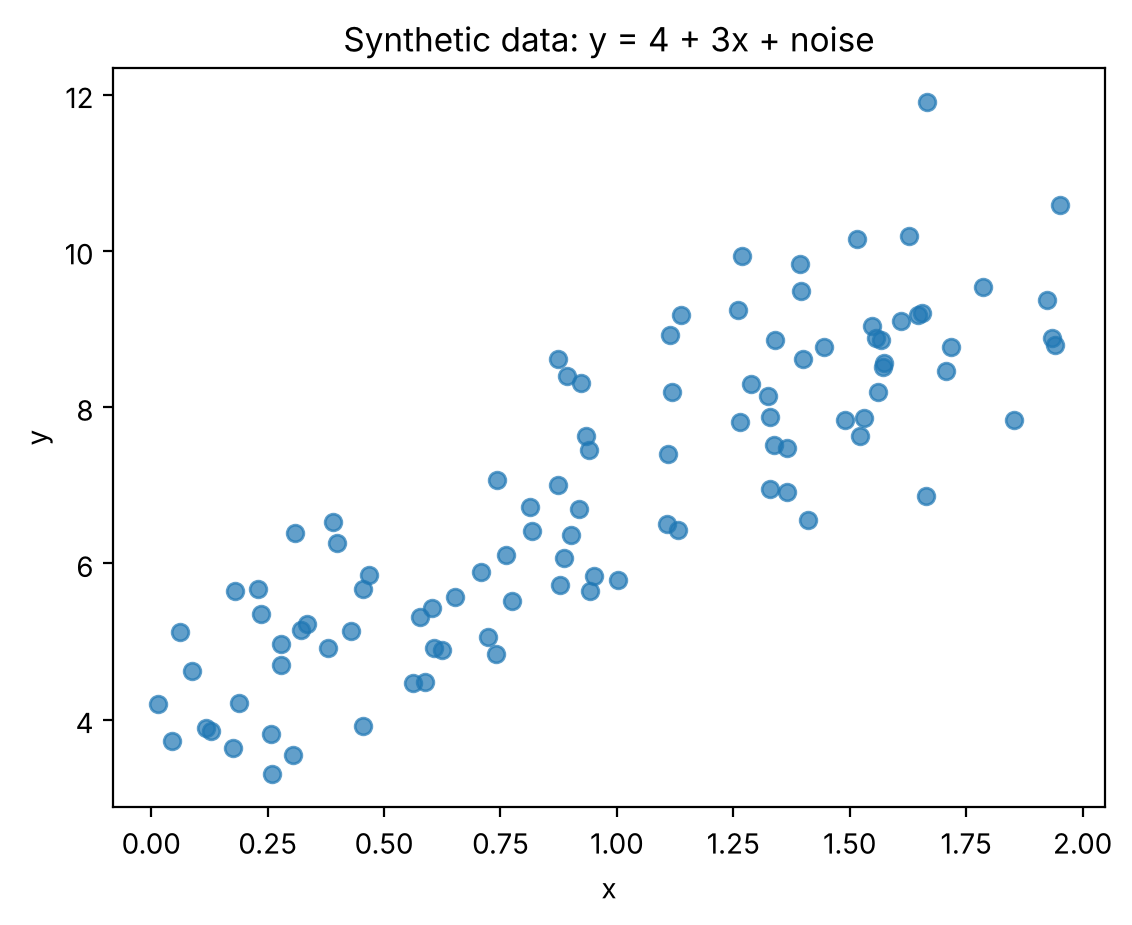

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
m = 100
x = 2 * rng.random(m)
y = 4 + 3 * x + rng.normal(0, 1, m)

plt.scatter(x, y, alpha=0.7)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Synthetic data: y = 4 + 3x + noise")
plt.show()

<div dir="rtl">

### ۲.۱ روش اول: معادله‌ی نرمال (جواب بسته)

برای رگرسیون خطی، جواب بهینه یک فرمول مستقیم دارد. اگر یک ستون ۱ به ماتریس $X$ اضافه کنیم تا بایاس هم جزو وزن‌ها شود:

</div>

$$\boldsymbol{\theta} = \left(X^\top X\right)^{-1} X^\top \mathbf{y}$$

In [2]:
X_b = np.c_[np.ones(m), x]          # add a column of ones for the bias term
theta_normal = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
print(f"Normal equation: b = {theta_normal[0]:.3f}, w = {theta_normal[1]:.3f}")

Normal equation: b = 3.949, w = 3.038


<div dir="rtl">

مقادیر به ۴ و ۳ نزدیک‌اند؛ اختلاف به خاطر نویز است. این روش ساده و دقیق است، ولی معکوس کردن ماتریس $X^\top X$ با $n$ ویژگی هزینه‌ای از مرتبه‌ی $n^3$ دارد و برای داده‌های خیلی بزرگ کند می‌شود. (در عمل به‌جای `inv` از `np.linalg.lstsq` استفاده می‌شود که پایدارتر است.)

### ۲.۲ روش دوم: گرادیان کاهشی (Gradient Descent)

**گرادیان کاهشی** روش اصلی آموزش تقریباً همه‌ی مدل‌های یادگیری ماشین، از جمله شبکه‌های عصبی، است. ایده: از یک نقطه‌ی تصادفی شروع کن و در هر قدم کمی در جهت **خلاف گرادیان** (شیب) تابع هزینه حرکت کن، مثل پایین آمدن از کوه در مه با دنبال کردن شیب زمین.

گرادیان MSE نسبت به پارامترها:

</div>

$$\frac{\partial J}{\partial w} = \frac{2}{m}\sum_{i=1}^{m}\left(\hat{y}^{(i)} - y^{(i)}\right)x^{(i)} \qquad \frac{\partial J}{\partial b} = \frac{2}{m}\sum_{i=1}^{m}\left(\hat{y}^{(i)} - y^{(i)}\right)$$

<div dir="rtl">

و قانون به‌روزرسانی با **نرخ یادگیری (learning rate)** $\alpha$:

</div>

$$w \leftarrow w - \alpha \frac{\partial J}{\partial w} \qquad b \leftarrow b - \alpha \frac{\partial J}{\partial b}$$

In [3]:
def gradient_descent(x, y, learning_rate=0.1, n_iterations=100):
    w, b = 0.0, 0.0
    m = len(x)
    history = []
    for _ in range(n_iterations):
        y_hat = w * x + b
        error = y_hat - y
        history.append(np.mean(error ** 2))
        dw = 2 / m * np.sum(error * x)
        db = 2 / m * np.sum(error)
        w -= learning_rate * dw
        b -= learning_rate * db
    return w, b, history

w, b, history = gradient_descent(x, y, learning_rate=0.1, n_iterations=500)
print(f"Gradient descent: b = {b:.3f}, w = {w:.3f}")

Gradient descent: b = 3.949, w = 3.038


<div dir="rtl">

گرادیان کاهشی به همان جواب معادله‌ی نرمال رسید. حالا اثر **نرخ یادگیری** را ببینیم؛ مهم‌ترین ابرپارامتر گرادیان کاهشی:

</div>

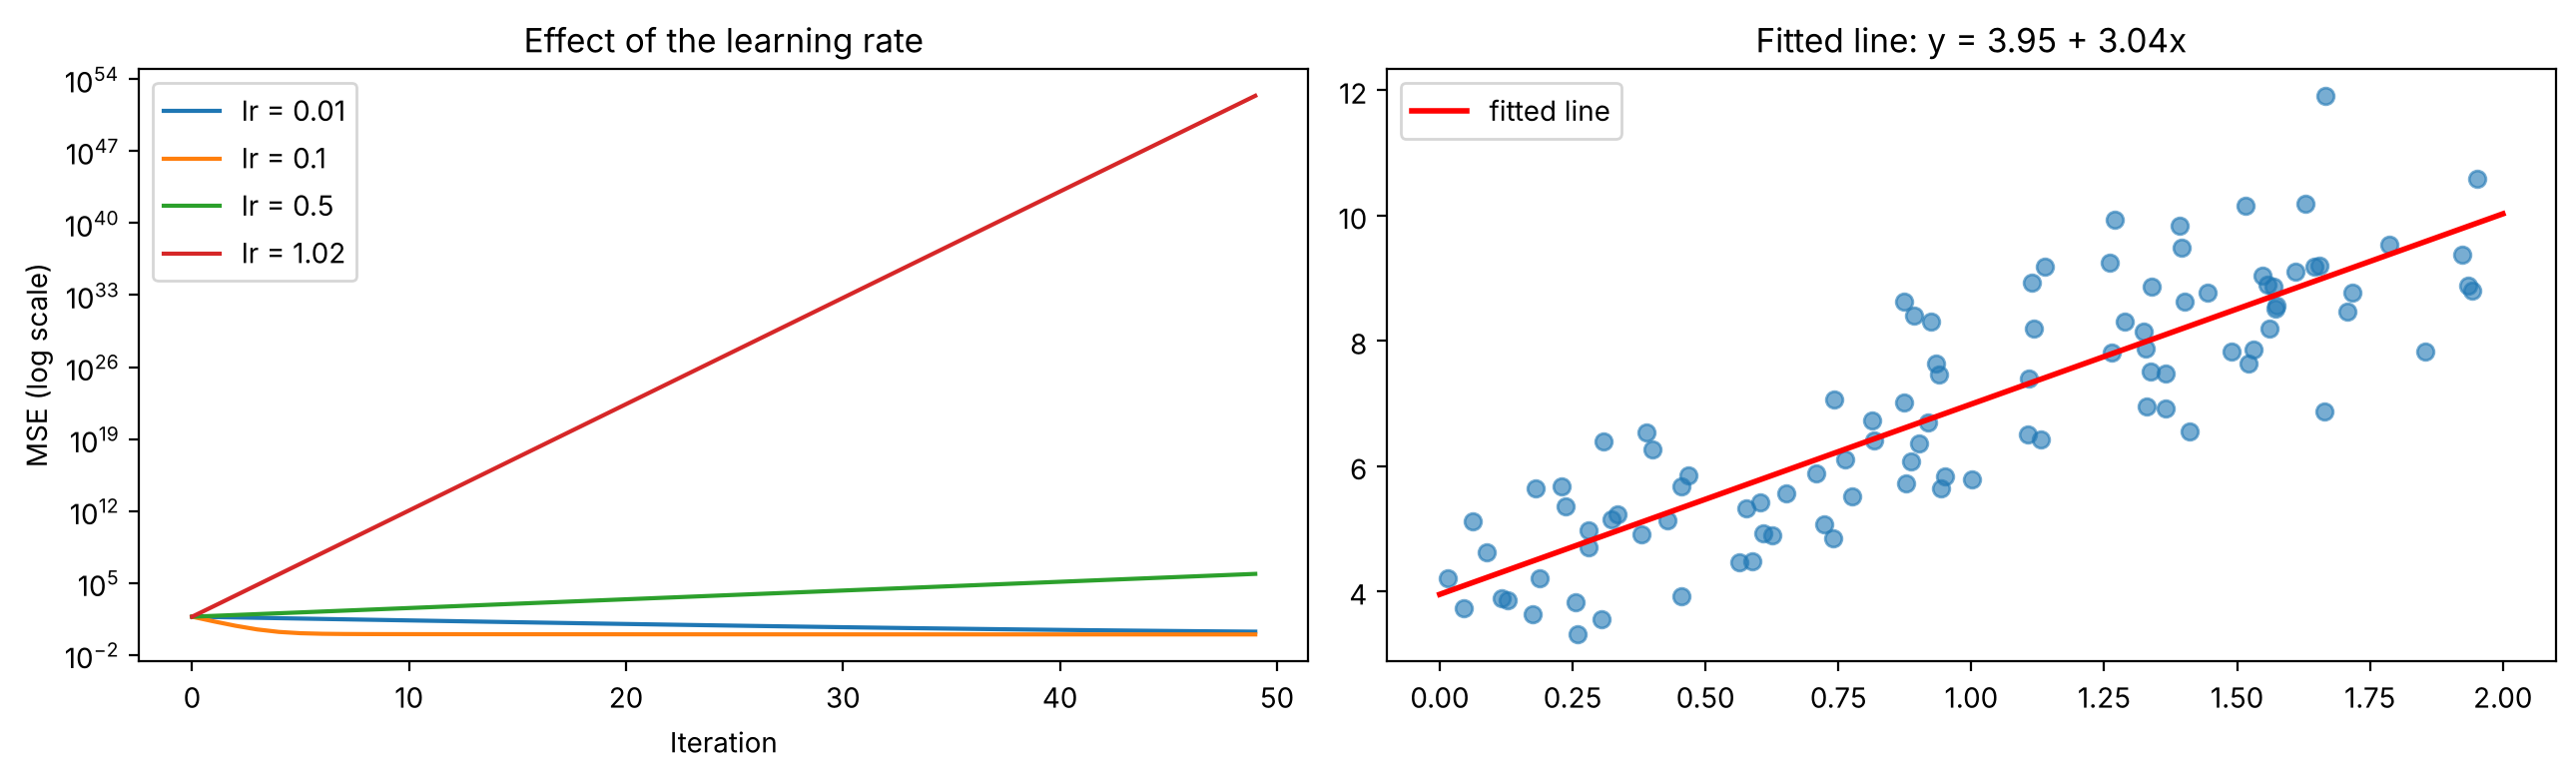

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for lr in [0.01, 0.1, 0.5, 1.02]:
    _, _, hist = gradient_descent(x, y, learning_rate=lr, n_iterations=50)
    axes[0].plot(hist, label=f"lr = {lr}")
axes[0].set_yscale("log")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("MSE (log scale)")
axes[0].set_title("Effect of the learning rate")
axes[0].legend()

axes[1].scatter(x, y, alpha=0.6)
x_line = np.linspace(0, 2, 100)
axes[1].plot(x_line, w * x_line + b, color="red", linewidth=2, label="fitted line")
axes[1].set_title(f"Fitted line: y = {b:.2f} + {w:.2f}x")
axes[1].legend()
plt.tight_layout()
plt.show()

<div dir="rtl">

- نرخ یادگیری **کوچک** (۰٫۰۱): همگرایی بسیار کند است.
- نرخ یادگیری **مناسب** (۰٫۱ و ۰٫۵): همگرایی سریع.
- نرخ یادگیری **بزرگ** (۱٫۰۲): الگوریتم از کمینه رد می‌شود، نوسان می‌کند و **واگرا** می‌شود؛ خطا به‌جای کم شدن زیاد می‌شود.

**نکته‌ی مهم:** گرادیان کاهشی به مقیاس ویژگی‌ها حساس است. اگر یک ویژگی بین ۰ و ۱ و دیگری بین ۰ و ۱۰۰۰ باشد، تابع هزینه به شکل یک دره‌ی کشیده درمی‌آید و همگرایی بسیار کند می‌شود. به همین دلیل قبل از گرادیان کاهشی همیشه **استانداردسازی** انجام می‌دهیم.

### ۲.۳ انواع گرادیان کاهشی

| نوع | داده‌ی استفاده‌شده در هر قدم | ویژگی |
|---|---|---|
| **دسته‌ای (Batch)** | کل داده | دقیق ولی کند برای داده‌ی بزرگ |
| **تصادفی (Stochastic, SGD)** | یک نمونه | سریع و پرنوسان |
| **دسته‌ی کوچک (Mini-batch)** | چند ده تا چند صد نمونه | تعادل بین این دو؛ استاندارد در شبکه‌های عصبی |

پیاده‌سازی بالا از نوع دسته‌ای بود.

</div>

<div dir="rtl">

## ۳. داده‌ی واقعی: قیمت مسکن کالیفرنیا

این مجموعه‌داده از سرشماری ۱۹۹۰ کالیفرنیا به دست آمده. هر سطر یک **محله (block group)** است و هدف، پیش‌بینی **میانه‌ی ارزش خانه‌ها** (`median_house_value`) در آن محله است.

</div>

In [5]:
DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Machine_Learning_Course/main/data/"
housing = pd.read_csv(DATA_URL + "housing.csv")
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [6]:
housing.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


<div dir="rtl">

- `total_bedrooms` ۲۰۷ مقدار گمشده دارد.
- `ocean_proximity` یک ویژگی دسته‌ای متنی است.

</div>

In [7]:
housing.describe().round(2)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.00,20640.00,20640.00,20640.00,20433.00,20640.00,20640.00,20640.00,20640.00
mean,-119.57,35.63,28.64,2635.76,537.87,1425.48,499.54,3.87,206855.82
std,2.00,2.14,12.59,2181.62,421.39,1132.46,382.33,1.90,115395.62
min,-124.35,32.54,1.00,2.00,1.00,3.00,1.00,0.50,14999.00
25%,-121.80,33.93,18.00,1447.75,296.00,787.00,280.00,2.56,119600.00
50%,-118.49,34.26,29.00,2127.00,435.00,1166.00,409.00,3.53,179700.00
75%,-118.01,37.71,37.00,3148.00,647.00,1725.00,605.00,4.74,264725.00
max,-114.31,41.95,52.00,39320.00,6445.00,35682.00,6082.00,15.00,500001.00


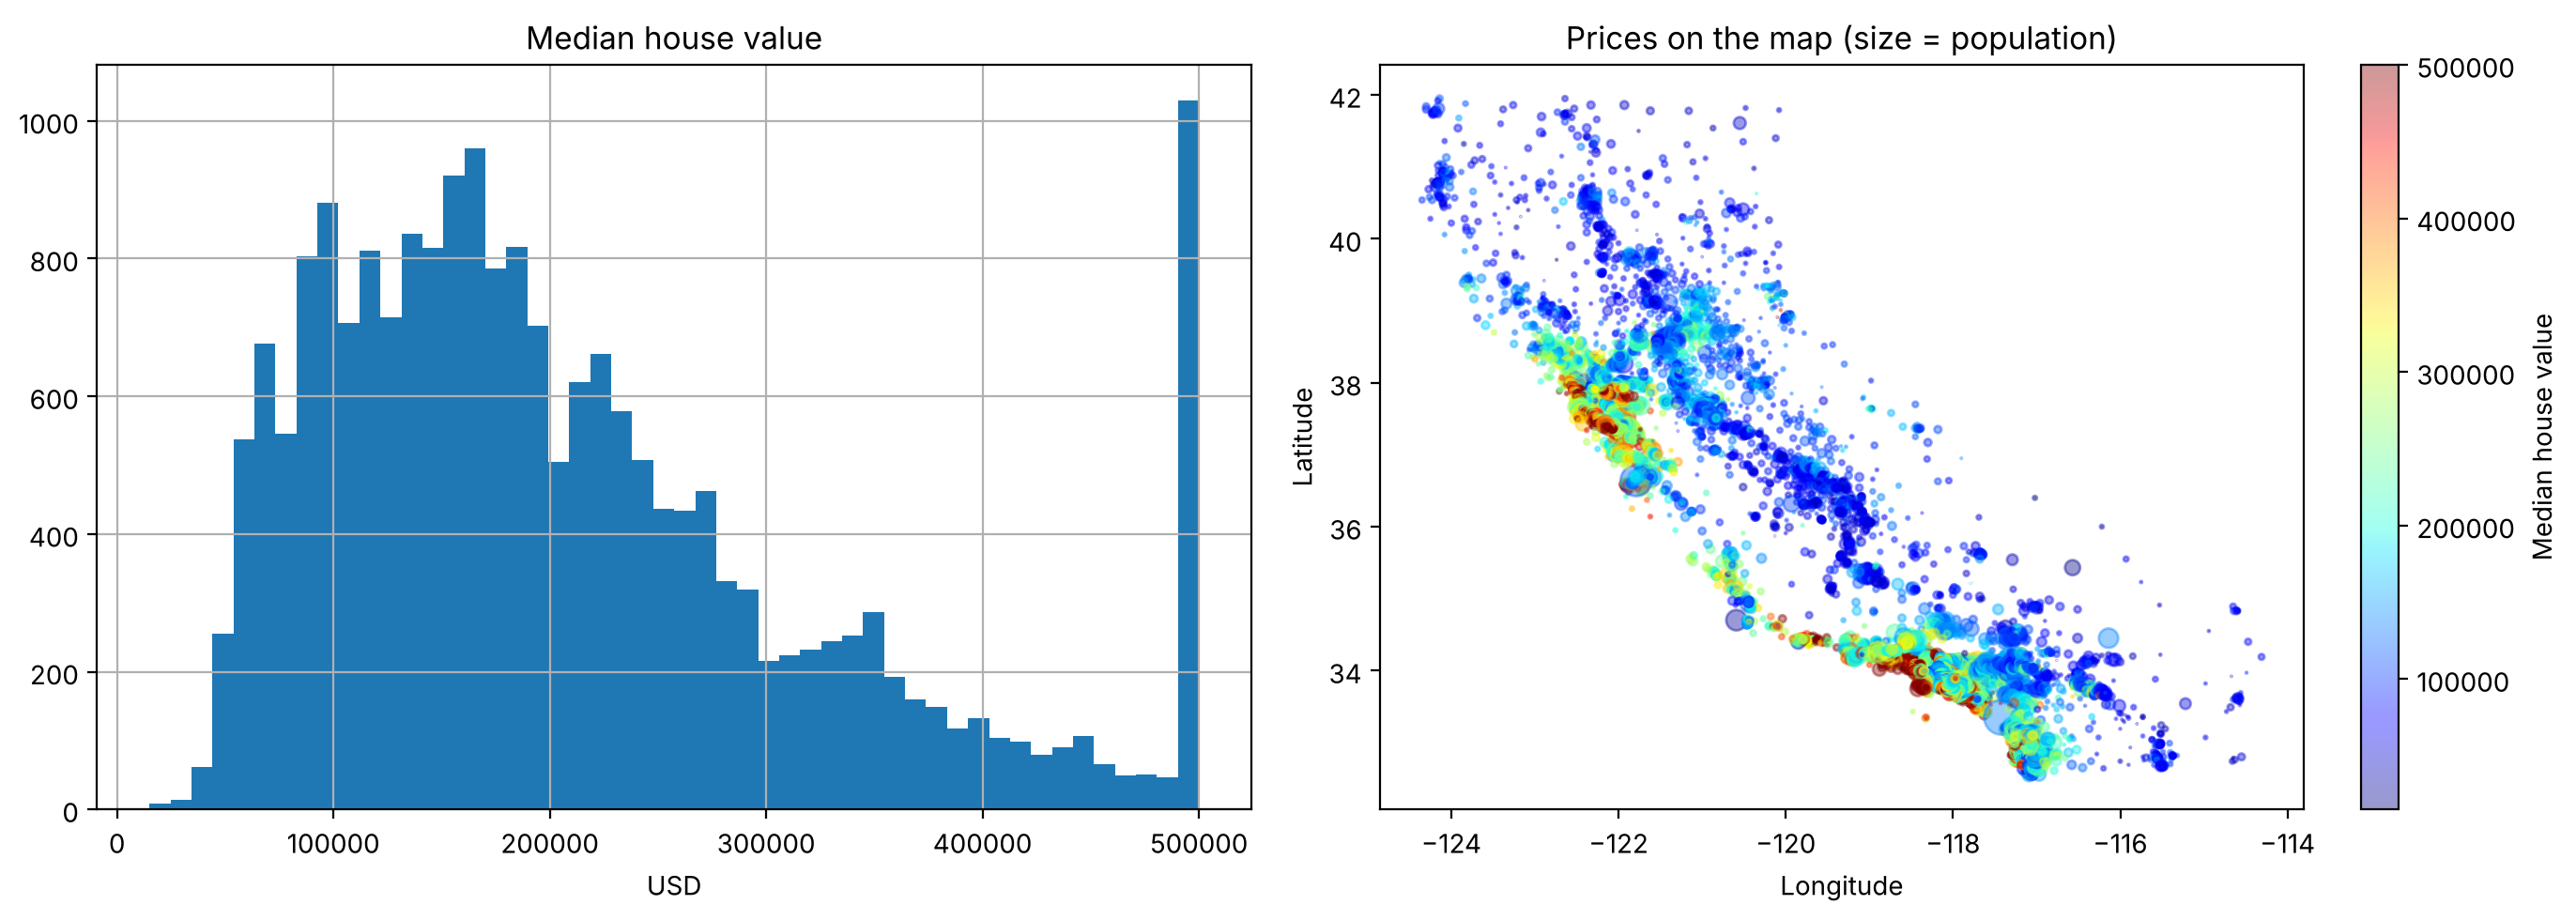

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
housing["median_house_value"].hist(bins=50, ax=axes[0])
axes[0].set_title("Median house value")
axes[0].set_xlabel("USD")

sc = axes[1].scatter(housing["longitude"], housing["latitude"], c=housing["median_house_value"],
                     s=housing["population"] / 200, cmap="jet", alpha=0.4)
plt.colorbar(sc, ax=axes[1], label="Median house value")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
axes[1].set_title("Prices on the map (size = population)")
plt.tight_layout()
plt.show()

<div dir="rtl">

دو نکته از این نمودارها:
1. در هیستوگرام، یک ستون بلند در ۵۰۰٬۰۰۰ دلار دیده می‌شود. مقادیر بالاتر در داده‌ی اصلی به این عدد **سقف زده شده‌اند (capped)**. مدل نمی‌تواند قیمت‌های بالاتر از این را یاد بگیرد. در یک پروژه‌ی واقعی باید با صاحب داده درباره‌ی این موضوع صحبت کرد.
2. روی نقشه، قیمت‌ها نزدیک ساحل و دو منطقه‌ی شهری بزرگ (سان‌فرانسیسکو و لس‌آنجلس) بالاترند. پس موقعیت جغرافیایی ویژگی مهمی است.

</div>

In [9]:
corr = housing.select_dtypes("number").corr()["median_house_value"].sort_values(ascending=False)
corr

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64

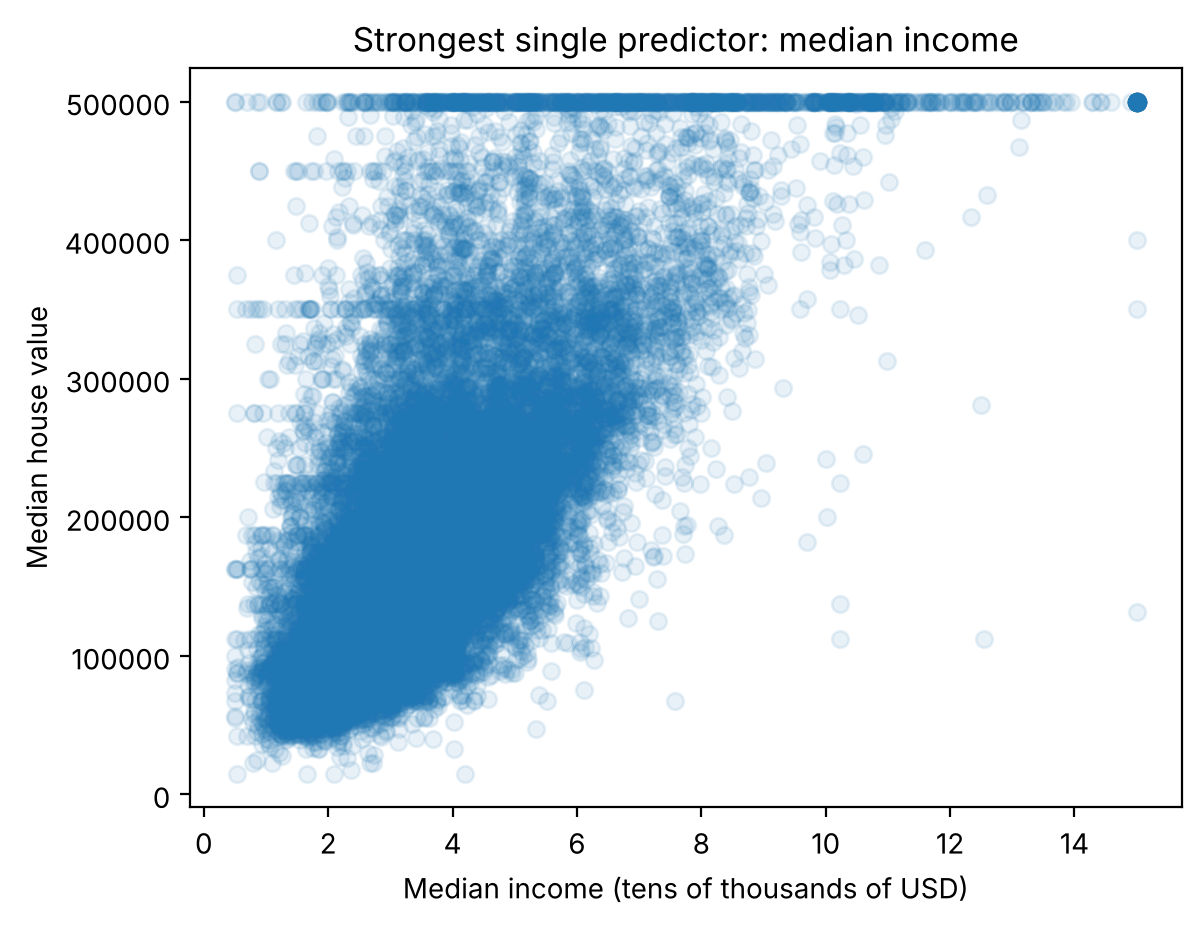

In [10]:
plt.scatter(housing["median_income"], housing["median_house_value"], alpha=0.1)
plt.xlabel("Median income (tens of thousands of USD)")
plt.ylabel("Median house value")
plt.title("Strongest single predictor: median income")
plt.show()

<div dir="rtl">

قوی‌ترین ویژگی، **میانه‌ی درآمد** است. رابطه تقریباً خطی است، ولی پراکندگی زیادی دارد و خط افقی سقف ۵۰۰٬۰۰۰ هم کاملاً پیداست.

### ۳.۱ مهندسی ویژگی

تعداد کل اتاق‌ها در یک محله به‌تنهایی معنای زیادی ندارد، چون به تعداد خانوارها بستگی دارد. نسبت‌ها معنادارترند:

</div>

In [11]:
housing["rooms_per_household"] = housing["total_rooms"] / housing["households"]
housing["bedrooms_ratio"] = housing["total_bedrooms"] / housing["total_rooms"]
housing["people_per_household"] = housing["population"] / housing["households"]

housing.select_dtypes("number").corr()["median_house_value"].sort_values(ascending=False)

median_house_value      1.000000
median_income           0.688075
rooms_per_household     0.151948
total_rooms             0.134153
housing_median_age      0.105623
households              0.065843
total_bedrooms          0.049686
people_per_household   -0.023737
population             -0.024650
longitude              -0.045967
latitude               -0.144160
bedrooms_ratio         -0.255880
Name: median_house_value, dtype: float64

<div dir="rtl">

ویژگی جدید `bedrooms_ratio` همبستگی منفی نسبتاً قوی دارد (خانه‌هایی که سهم اتاق خواب کمتری دارند، معمولاً بزرگ‌تر و گران‌ترند)؛ بسیار قوی‌تر از `total_rooms` یا `total_bedrooms` خام.

### ۳.۲ تقسیم داده و ساختن Pipeline

</div>

In [12]:
from sklearn.model_selection import train_test_split

X = housing.drop(columns="median_house_value")
y = housing["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (16512, 12)  Test: (4128, 12)


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression

numeric_features = X.select_dtypes("number").columns.tolist()
categorical_features = ["ocean_proximity"]

preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

lin_reg = Pipeline([("preprocess", preprocessor), ("model", LinearRegression())])
lin_reg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['longitude','latitude','housing_median_age',...,'rooms_per_household', 'bedrooms_ratio','people_per_household']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically

<div dir="rtl">

## ۴. ارزیابی مدل رگرسیون

معیارهای اصلی:

- **MAE (میانگین قدر مطلق خطا):** به‌طور متوسط چقدر اشتباه می‌کنیم؟ با همان واحد هدف (دلار) و قابل فهم برای همه.
- **RMSE (ریشه‌ی میانگین مربعات خطا):** مثل MAE با واحد دلار، ولی خطاهای بزرگ را بیشتر جریمه می‌کند.
- **ضریب تعیین $R^2$:** چه سهمی از واریانس هدف را مدل توضیح می‌دهد. یک یعنی پیش‌بینی کامل، صفر یعنی به خوبیِ پیش‌بینی همیشگی میانگین، و مقدار منفی یعنی بدتر از آن.

</div>

$$\text{MAE} = \frac{1}{m}\sum\left|y - \hat{y}\right| \qquad \text{RMSE} = \sqrt{\frac{1}{m}\sum\left(y - \hat{y}\right)^2} \qquad R^2 = 1 - \frac{\sum\left(y - \hat{y}\right)^2}{\sum\left(y - \bar{y}\right)^2}$$

<div dir="rtl">

مثل همیشه، اول یک مدل پایه: پیش‌بینی میانگین قیمت داده‌ی آموزش برای همه‌ی محله‌ها.

</div>

In [14]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

def regression_report(name, model):
    y_pred = model.predict(X_test)
    return {
        "model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": root_mean_squared_error(y_test, y_pred),
        "R2": r2_score(y_test, y_pred),
    }

baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
pd.DataFrame([
    regression_report("Baseline (mean)", baseline),
    regression_report("Linear regression", lin_reg),
]).round(3)

,model,MAE,RMSE,R2
0,Baseline (mean),90606.855,114485.635,-0.000
1,Linear regression,49645.492,69127.038,0.635


<div dir="rtl">

رگرسیون خطی حدود ۶۴٪ از واریانس قیمت‌ها را توضیح می‌دهد و خطای متوسط آن حدود ۵۰ هزار دلار است، در مقابل حدود ۹۰ هزار دلار مدل پایه. پیشرفت خوبی است، ولی هنوز خطای زیادی داریم. در جلسه‌های بعد با مدل‌های قوی‌تر این عدد را بهتر می‌کنیم.

### ۴.۱ تحلیل باقیمانده‌ها

**باقیمانده (residual)** یعنی $y - \hat{y}$. نمودار باقیمانده‌ها نشان می‌دهد مدل کجا و چطور اشتباه می‌کند.

</div>

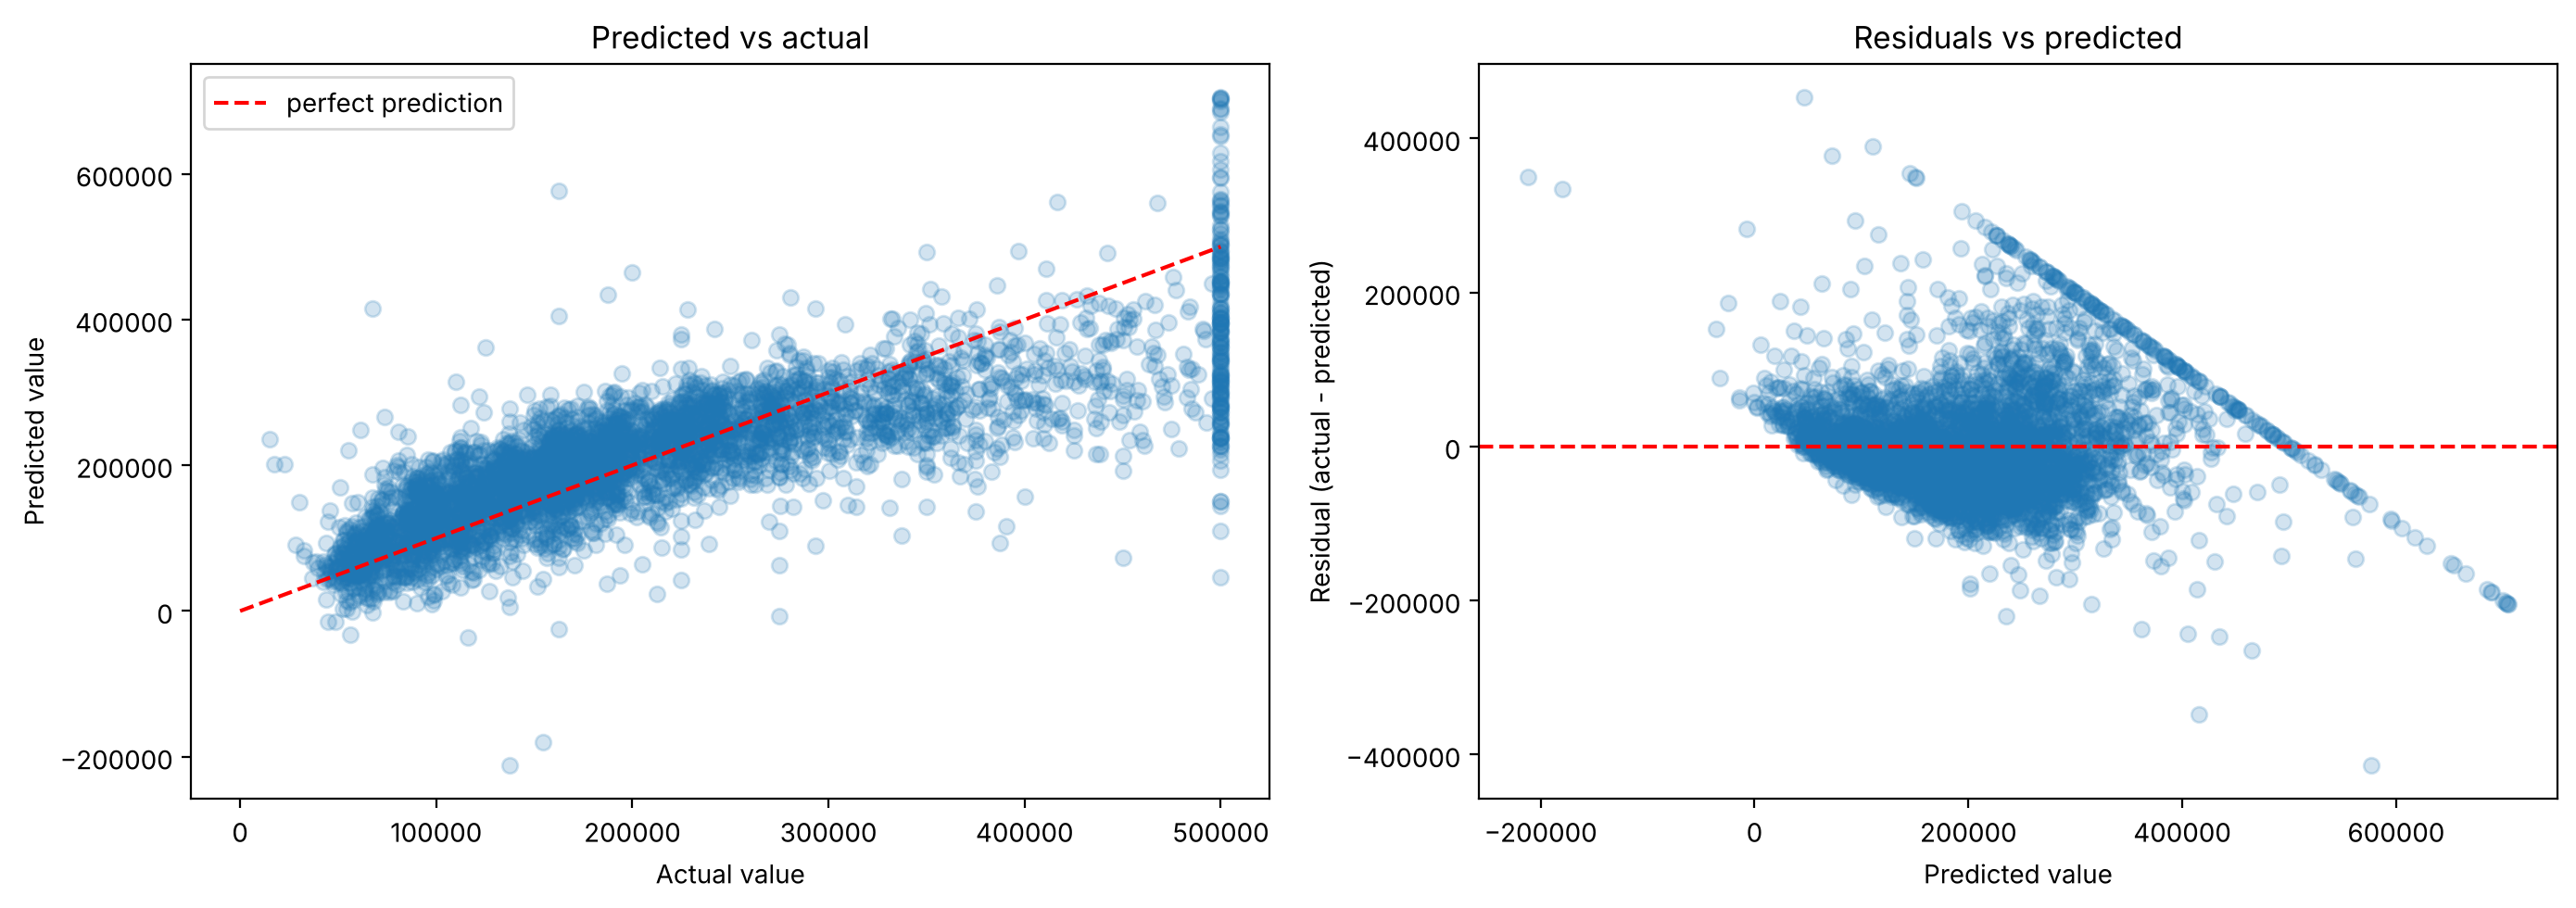

In [15]:
y_pred = lin_reg.predict(X_test)
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, y_pred, alpha=0.2)
axes[0].plot([0, 500_000], [0, 500_000], color="red", linestyle="--", label="perfect prediction")
axes[0].set_xlabel("Actual value")
axes[0].set_ylabel("Predicted value")
axes[0].set_title("Predicted vs actual")
axes[0].legend()

axes[1].scatter(y_pred, residuals, alpha=0.2)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted value")
axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("Residuals vs predicted")
plt.tight_layout()
plt.show()

<div dir="rtl">

- اگر مدل مناسب باشد، باقیمانده‌ها باید **به‌طور تصادفی** حول صفر پخش شوند.
- اینجا الگو داریم: خط مورب در نمودار باقیمانده‌ها اثر **سقف ۵۰۰٬۰۰۰** است، و پیش‌بینی‌های بالاتر از ۵۰۰٬۰۰۰ یا کمتر از صفر نشان می‌دهند که رابطه کاملاً خطی نیست.
- این الگوها می‌گویند مدل خطی برای این داده کمی **ساده** است (کم‌برازش). در جلسه‌ی بعد سراغ مدل‌های انعطاف‌پذیرتر می‌رویم.

### ۴.۲ تفسیر ضرایب

یکی از بزرگ‌ترین مزیت‌های رگرسیون خطی **تفسیرپذیری** آن است. چون ویژگی‌های عددی استاندارد شده‌اند، هر ضریب نشان می‌دهد با افزایش یک انحراف معیار در آن ویژگی (با ثابت ماندن بقیه)، قیمت پیش‌بینی‌شده چقدر تغییر می‌کند.

</div>

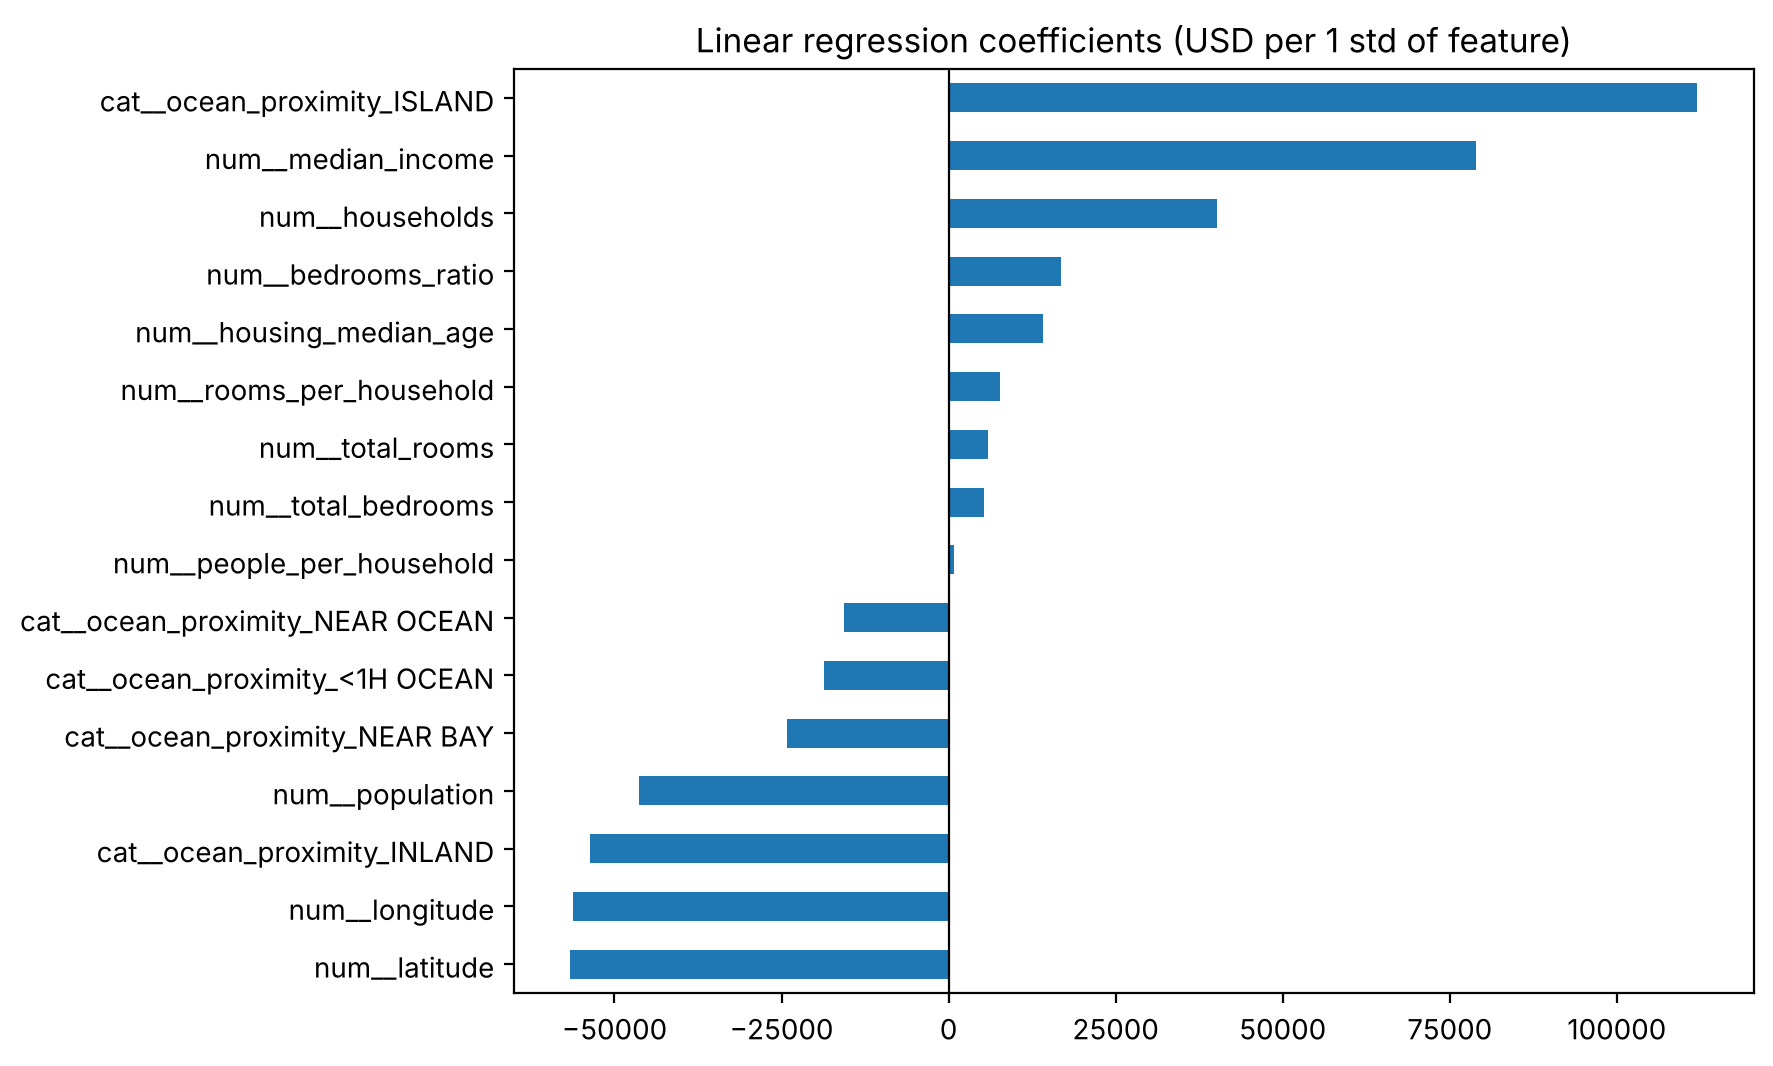

In [16]:
names = lin_reg.named_steps["preprocess"].get_feature_names_out()
coefs = pd.Series(lin_reg.named_steps["model"].coef_, index=names).sort_values()
coefs.plot.barh(figsize=(8, 6))
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Linear regression coefficients (USD per 1 std of feature)")
plt.show()

<div dir="rtl">

**هشدار درباره‌ی تفسیر ضرایب:**

- وقتی ویژگی‌ها با هم همبستگی شدید دارند (**هم‌خطی یا multicollinearity**)، ضرایب ناپایدار می‌شوند و ممکن است علامت عجیبی بگیرند. مثلاً `population` ضریب منفی بزرگ و `households` ضریب مثبت بزرگ گرفته است، در حالی که این دو تقریباً همبستگی کامل دارند؛ مدل اثر آن‌ها را بین هم تقسیم کرده و تک‌تک این ضرایب معنای مستقلی ندارند.
- `bedrooms_ratio` به‌تنهایی همبستگی **منفی** با قیمت داشت، ولی در مدل چندگانه ضریبش **مثبت** است. ضریب در رگرسیون چندگانه یعنی اثر ویژگی **با ثابت ماندن بقیه‌ی ویژگی‌ها**، که با همبستگی ساده فرق دارد.
- ضریب بسیار بزرگ `ocean_proximity_ISLAND` از روی فقط چند محله‌ی جزیره‌ای تخمین زده شده و قابل اعتماد نیست.

در جلسه‌ی بعد، **منظم‌سازی** را برای کنترل این مشکل‌ها یاد می‌گیریم.

</div>

<div dir="rtl">

### ۴.۳ نگاه آماری با statsmodels

در آمار کلاسیک، رگرسیون خطی با آزمون‌های معناداری همراه است. کتابخانه‌ی `statsmodels` خلاصه‌ی کاملی شامل خطای استاندارد، آماره‌ی $t$ و **p-value** هر ضریب می‌دهد. p-value کوچک (معمولاً کمتر از ۰٫۰۵) یعنی شواهد کافی داریم که ضریب آن ویژگی صفر نیست. اینجا برای سادگی فقط چند ویژگی عددی را استفاده می‌کنیم:

</div>

In [17]:
import statsmodels.api as sm

cols = ["median_income", "housing_median_age", "rooms_per_household", "bedrooms_ratio"]
train_data = pd.concat([X_train[cols], y_train], axis=1).dropna()
X_sm = sm.add_constant(train_data[cols])
ols = sm.OLS(train_data["median_house_value"], X_sm).fit()
print(ols.summary().tables[1])
print(f"\nR-squared: {ols.rsquared:.3f}")

                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const               -1.545e+05   4850.619    -31.856      0.000   -1.64e+05   -1.45e+05
median_income        5.272e+04    403.582    130.640      0.000    5.19e+04    5.35e+04
housing_median_age   1611.5048     48.551     33.192      0.000    1516.340    1706.669
rooms_per_household   335.5657    282.986      1.186      0.236    -219.117     890.249
bedrooms_ratio       5.129e+05   1.39e+04     36.999      0.000    4.86e+05     5.4e+05

R-squared: 0.553


<div dir="rtl">

در یادگیری ماشین، تمرکز ما بیشتر بر **دقت پیش‌بینی روی داده‌ی آزمون** است تا معناداری آماری ضرایب. ولی برای فهمیدن رابطه‌ها، مخصوصاً در کارهای پژوهشی، این جدول بسیار ارزشمند است.

</div>

<div dir="rtl">

## ۵. گرادیان کاهشی تصادفی در scikit-learn

برای داده‌های بسیار بزرگ، `SGDRegressor` همان رگرسیون خطی را با گرادیان کاهشی تصادفی آموزش می‌دهد. توجه کنید که بدون استانداردسازی، SGD به‌درستی همگرا نمی‌شود؛ اینجا Pipeline این کار را برای ما انجام می‌دهد.

</div>

In [18]:
from sklearn.linear_model import SGDRegressor

sgd_reg = Pipeline([
    ("preprocess", preprocessor),
    ("model", SGDRegressor(max_iter=1000, tol=1e-4, random_state=42)),
])
sgd_reg.fit(X_train, y_train)
pd.DataFrame([regression_report("Linear regression (closed form)", lin_reg),
              regression_report("SGDRegressor", sgd_reg)]).round(3)

,model,MAE,RMSE,R2
0,Linear regression (closed form),49645.492,69127.038,0.635
1,SGDRegressor,49858.596,69784.507,0.628


<div dir="rtl">

هر دو روش به نتیجه‌ی تقریباً یکسانی می‌رسند.

## ۶. فرض‌های رگرسیون خطی

1. **خطی بودن:** رابطه‌ی ویژگی‌ها و هدف خطی است.
2. **استقلال خطاها:** خطای هر نمونه مستقل از بقیه است.
3. **همسانی واریانس (Homoscedasticity):** پراکندگی خطاها در همه‌ی بازه‌ی پیش‌بینی ثابت است.
4. **نرمال بودن خطاها:** برای آزمون‌های آماری مثل p-value اهمیت دارد.
5. **نبود هم‌خطی شدید** بین ویژگی‌ها، برای تفسیر پایدار ضرایب.

برای **پیش‌بینی**، نقض این فرض‌ها همیشه فاجعه نیست، ولی نشانه‌ای است که شاید مدل بهتری وجود دارد.

## ۷. جمع‌بندی

- رگرسیون خطی با کمینه کردن MSE بهترین خط (یا ابرصفحه) را پیدا می‌کند.
- دو راه آموزش: معادله‌ی نرمال (دقیق، برای داده‌ی کوچک و متوسط) و گرادیان کاهشی (عمومی و مقیاس‌پذیر).
- نرخ یادگیری مهم‌ترین ابرپارامتر گرادیان کاهشی است و استانداردسازی برای آن ضروری است.
- مدل رگرسیون را با MAE، RMSE و $R^2$ روی داده‌ی آزمون و در مقایسه با مدل پایه بسنجید.
- نمودار باقیمانده‌ها نشان می‌دهد مدل کجا ضعف دارد.

## ۸. تمرین

1. تابع `gradient_descent` را طوری تغییر کنید که **mini-batch** باشد: در هر قدم فقط ۱۶ نمونه‌ی تصادفی استفاده شود. نمودار خطا را با نسخه‌ی دسته‌ای مقایسه کنید.
2. رگرسیون خطی را فقط با ویژگی `median_income` آموزش دهید. $R^2$ چقدر است؟ ویژگی‌های دیگر چقدر کمک کرده‌اند؟
3. محله‌هایی را که قیمتشان دقیقاً ۵۰۰٬۰۰۱ است از داده‌ی آموزش و آزمون حذف کنید و مدل را دوباره آموزش دهید. معیارها چطور تغییر می‌کنند؟
4. به‌جای پیش‌بینی مستقیم قیمت، لگاریتم قیمت را پیش‌بینی کنید (`np.log`) و سپس با `np.exp` برگردانید. MAE بهتر می‌شود؟ (راهنمایی: `TransformedTargetRegressor`)

</div>